## Identification results processing

JUMPlion takes a precursor-level identification report as one of its inputs and performs a series of steps to process the report for further analysis. These steps include:

 - Filtering precursors based on the number of runs in which they are identified
 - Building the RT/IM prediction model for each individual run and predicting RT/IM for precursors that are reported as missing
 - Selecting high-confidence precursors (based on precursor Q-value and the number of runs in which a precursor is identified) for mass calibration and IM window determination
 - Determining the number of data points to extract for an XIC based on RT prediction accuracy

The **precursor-level identification report** is a tabular file listing the identified precursors for each run, along with their retention time (RT), ion mobility (IM, for timsTOF data), and precursor-level Q-value. Supported file formats include .csv, .tsv, and .parquet. If using DIA-NN outputs, the report.parquet file can be used directly.

In [10]:
import numpy as np
import pandas as pd

# Read the id report file
is_tims = True
id_file = r"../tests/id_report_toy.parquet"
required_columns = ['Run', 'Precursor.Id', 'RT', 'Q.Value']
if is_tims:
    required_columns = required_columns + ['IM']
id_df = pd.read_parquet(id_file, columns=required_columns)

In [11]:
id_df.head(6)

,Run,Precursor.Id,RT,Q.Value,IM
0,H6_3_D10_660,AAAAAAAAAAAPPAPPEGASPGDSAR3,14.355443,0.000875,1.014694
1,H6_4_D11_661,AAAAAAAAAAAPPAPPEGASPGDSAR3,14.276978,0.000583,1.018494
2,H6_5_D12_662,AAAAAAAAAAAPPAPPEGASPGDSAR3,14.211516,0.000520,1.014414
3,H6_6_E1_663,AAAAAAAAAAAPPAPPEGASPGDSAR3,14.179474,0.000568,1.017563
4,H7_2_E4_666,AAAAAAAAAAAPPAPPEGASPGDSAR3,14.163171,0.000815,1.026169
5,H7_3_E5_667,AAAAAAAAAAAPPAPPEGASPGDSAR3,14.212599,0.002617,1.017643


### Select precursors for quantification
Related parameter: min_runs_quant. The minimum number of runs in which a precursor must be identified to be considered for quantification.

In [12]:
min_runs_quant = 3
rt_mat = id_df.pivot(index='Precursor.Id', columns='Run', values='RT')
print(f"Before filtering: {len(rt_mat)} precursors")
rt_mat = rt_mat[(rt_mat.shape[1] - rt_mat.isna().sum(axis=1)) >= min_runs_quant]
print(f"After filtering: {len(rt_mat)} precursors")
print("RT matrix before prediction: ")
rt_mat.head(6)

Before filtering: 23465 precursors
After filtering: 23204 precursors
RT matrix before prediction: 


Run,H6_3_D10_660,H6_4_D11_661,H6_5_D12_662,H6_6_E1_663,H7_2_E4_666,H7_3_E5_667,H7_4_E6_668,H7_5_E7_669,H8_1_E10_672,H8_2_E11_673,H8_3_E12_674,H8_4_F1_675
Precursor.Id,,,,,,,,,,,,
AAAAAAAAAAAPPAPPEGASPGDSAR3,14.355443,14.276978,14.211516,14.179474,14.163171,14.212599,14.197556,14.164258,14.181807,14.180182,14.115888,14.181341
AAAADILPVLLK2,34.641689,34.642933,34.625931,34.592979,34.560818,34.498718,34.467770,34.530033,34.404064,34.386368,34.353931,34.324024
AAAEVLFRPNPHLLSEDR4,23.272438,23.305504,23.208574,23.271967,23.111540,23.113611,23.098444,23.080904,22.810789,22.825165,22.872595,22.778400
AAAGELQEDSGLC(UniMod:4)VLAR2,25.140625,25.221487,25.060736,25.156275,25.043690,25.029806,24.998707,25.029030,24.870806,24.853243,24.836758,24.822475
AAAGLGGGDSGDGTAR2,6.420696,6.438160,6.420632,6.388623,6.372499,NaN,NaN,6.405771,NaN,6.373291,6.389084,6.374893
AAAGTYEGVK2,6.456307,NaN,NaN,NaN,NaN,NaN,NaN,6.409324,6.362402,6.376844,6.408620,6.362463


### RT/IM prediction
Related parameter: min_runs_model — the minimum number of runs in which a precursor must be identified to be used for building the RT/IM prediction model.

Each precursor has an iRT value in the library. A model is built using the experimental RT and the library iRT. This model is then used to predict the experimental RT based on the iRT for precursors that lack an experimental RT. Similarly, the same approach can be applied to predict the experimental IM for precursors missing IM values.

In [13]:
from jumplion.id_results_processing import collect_model_data, modeling_and_prediction, adjust_prediction_outliers

# Read spectral library
lib_file = r"../tests/spectral_library_toy.parquet"
lib_df = pd.read_parquet(lib_file)

# Only use the iRT/iIM info in the library here
if is_tims:
    lib_df_uniq_prec = lib_df[['Precursor.Id', 'RT', 'IM', 'Precursor.Mz']].copy()
else:
    lib_df_uniq_prec = lib_df[['Precursor.Id', 'RT', 'Precursor.Mz']].copy()
lib_df_uniq_prec.drop_duplicates(subset=['Precursor.Id'], inplace=True, ignore_index=True)

# Modeling and prediction
min_runs_model = 3
data_type="rt"
rt_dict, rt_segments = collect_model_data(rt_mat, min_runs_model, lib_df_uniq_prec, data_type)

RT prediction model for run H6_3_D10_660:


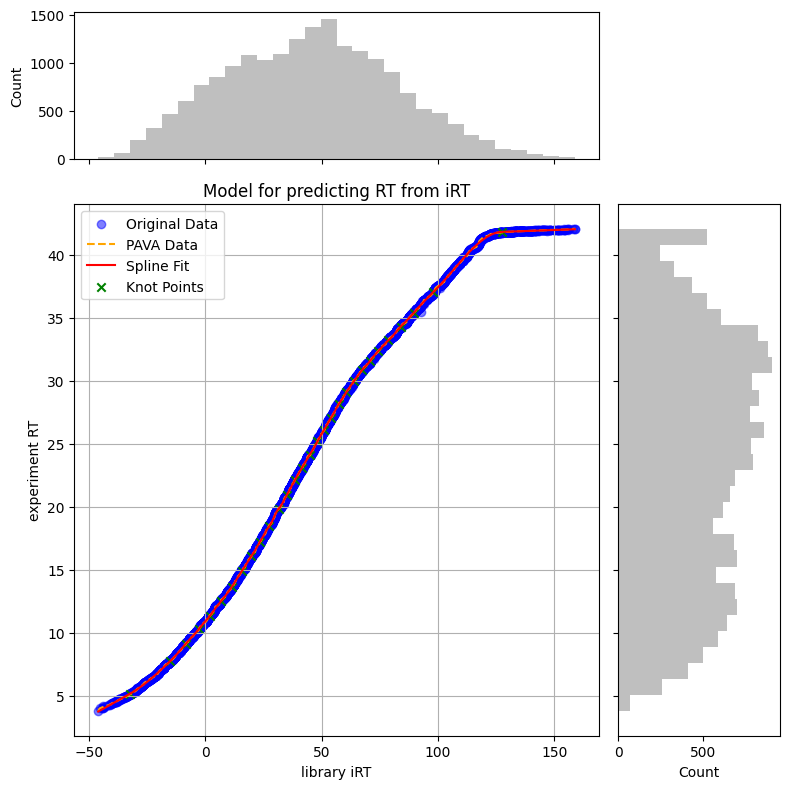

RT prediction accuracy for 80.0% precursors: 0.0578
Predicted experimental RT for iRT of 51.25 is 26.153.


In [15]:
from jumplion.calibration import calc_spline, refine_spline, convert_to_arrays, check_model_accuracy, spline_fitting_plot

# take one run as an example
run_name = 'H6_3_D10_660'
delta_percentile = 0.8
model_data = rt_dict[run_name]
x, y = convert_to_arrays(model_data)
model_coeff, model_points = refine_spline(x, y, rt_segments)
model_acc = check_model_accuracy(model_data, model_coeff, model_points, delta_percentile)
print(f"RT prediction model for run {run_name}:")
spline_fitting_plot(model_data, 
                    model_coeff, 
                    model_points, 
                    model_acc, 
                    show_window=False, 
                    model=data_type.upper(), 
                    out_dir="", 
                    run_name=run_name,
                    save_plot=False)
print(f"{data_type.upper()} prediction accuracy for {delta_percentile * 100}% precursors: {np.round(model_acc, 4)}")

# prediction
lib_iRT = 51.25
predicted_rt = calc_spline(model_coeff, model_points, x=lib_iRT)
print(f"Predicted experimental RT for iRT of {lib_iRT} is {np.round(predicted_rt, 3)}.")

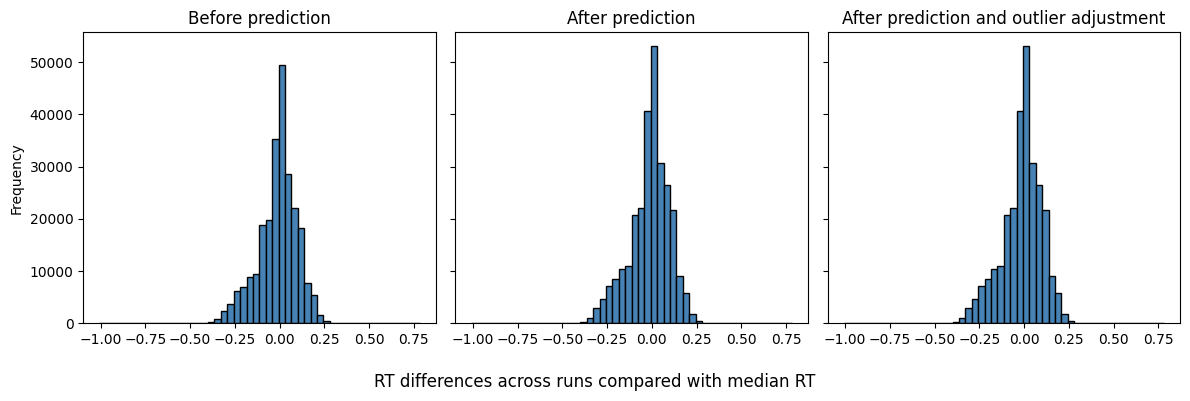

RT matrix after prediction: 


Run,H6_3_D10_660,H6_4_D11_661,H6_5_D12_662,H6_6_E1_663,H7_2_E4_666,H7_3_E5_667,H7_4_E6_668,H7_5_E7_669,H8_1_E10_672,H8_2_E11_673,H8_3_E12_674,H8_4_F1_675
Precursor.Id,,,,,,,,,,,,
AAAAAAAAAAAPPAPPEGASPGDSAR3,14.355443,14.276978,14.211516,14.179474,14.163171,14.212599,14.197556,14.164258,14.181807,14.180182,14.115888,14.181341
AAAADILPVLLK2,34.641689,34.642933,34.625931,34.592979,34.560818,34.498718,34.467770,34.530033,34.404064,34.386368,34.353931,34.324024
AAAEVLFRPNPHLLSEDR4,23.272438,23.305504,23.208574,23.271967,23.111540,23.113611,23.098444,23.080904,22.810789,22.825165,22.872595,22.778400
AAAGELQEDSGLC(UniMod:4)VLAR2,25.140625,25.221487,25.060736,25.156275,25.043690,25.029806,24.998707,25.029030,24.870806,24.853243,24.836758,24.822475
AAAGLGGGDSGDGTAR2,6.420696,6.438160,6.420632,6.388623,6.372499,6.357172,6.301412,6.405771,6.371650,6.373291,6.389084,6.374893
AAAGTYEGVK2,6.456307,6.507669,6.468745,6.432690,6.433951,6.384584,6.328118,6.409324,6.362402,6.376844,6.408620,6.362463


In [16]:
# Do the above for all runs
rt_mat_pred = modeling_and_prediction(rt_dict, rt_segments, rt_mat, 
                                      lib_df_uniq_prec, data_type="rt", 
                                      out_dir="", save_plot=False, 
                                      save_model=False)
# Adjust RT prediction outliers
rt_mat_pred = adjust_prediction_outliers(rt_mat_pred, rt_mat, 5, save_plot=False)
print("RT matrix after prediction: ")
rt_mat_pred.head(6)

### Select high-confidence precursors for mass calibration and IM window determination
Related parameters: min_qvalue_cal, min_runs_cal, max_mass_cal.

To select precursors for mass calibration, we aim to include those that can be confidently identified in the majority of runs.

In [17]:
import random

min_qvalue_cal = 1e-4
min_runs_cal = 6
max_mass_cal = 5000

id_df_cal = id_df[id_df['Q.Value'] < min_qvalue_cal]
rt_mat_cal = rt_mat[(rt_mat.shape[1] - rt_mat.isna().sum(axis=1)) >= min_runs_cal]
mass_cal_precs = list(set(rt_mat_cal.index.values).intersection(set(id_df_cal['Precursor.Id'].drop_duplicates())))
print(f"{len(mass_cal_precs)} precursors with Q-values < {min_qvalue_cal} are detected in at least (>=) {min_runs_cal} runs")
random.seed(42)
mass_cal_precs = random.sample(mass_cal_precs, min(len(mass_cal_precs), max_mass_cal))
print(f"{len(mass_cal_precs)} of them are randomly selected for mass calibration\n")

11586 precursors with Q-values < 0.0001 are detected in at least (>=) 6 runs
5000 of them are randomly selected for mass calibration



### Determining the number of data points to extract for an XIC

In [18]:
cycle_time = 0.016 # min
print(f"Cycle time: {cycle_time} ({np.round(cycle_time*60, 3)} seconds)")
 
average_model_acc = 0.057
average_model_acc_n_points = int(np.round(average_model_acc / cycle_time))
print(f"Average RT prediction accuracy in terms of the number of data points in XICs: {average_model_acc_n_points}")

MinXICPoints = 20
n_xic_points = max(MinXICPoints, average_model_acc_n_points * 4 + 1)
print(f"Number of data points to extract for a XIC set to: {n_xic_points}\n")

Cycle time: 0.016 (0.96 seconds)
Average RT prediction accuracy in terms of the number of data points in XICs: 4
Number of data points to extract for a XIC set to: 20

